# Green area in Vietnamese cities, from satellite images

**Question.** How does the amount of green vegetation change through the year in different parts of Vietnam, and does it behave the way a clear-sky reference city does?

For each satellite image (Landsat-8 and Sentinel-2, 2016-2021) the green area inside a region is the area of pixels with NDVI > 0.3, in **square kilometres** (that is what the collection code computes). Regions: Hanoi city, Hanoi outskirts, Saigon (Ho Chi Minh City) city, Saigon outskirts, Khanh Hoa province, and **Seville, Spain** as a reference: a city with little cloud all year, so its measurements should show the real seasonal cycle.

This notebook redraws the views from the original study from the data in `data/`, then adds two checks that are marked **(added)**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
NAMES = {"hanoi_city": "Hanoi city", "hanoi_outskirts": "Hanoi outskirts", "saigon_city": "Saigon city",
         "saigon_outskirts": "Saigon outskirts", "khanh_hoa": "Khanh Hoa", "seville": "Seville (reference)"}

def load(folder, prefix=""):
    frames = []
    for path in sorted(Path(folder).glob("*.csv")):
        stem = path.stem.replace(prefix, "")
        region, satellite = stem.rsplit("_", 1)
        df = pd.read_csv(path)
        df["region"], df["satellite"] = NAMES[region], satellite
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

raw = load("../data/raw")
clean = load("../data/cleaned", prefix="cleaned_")
raw.groupby(["region", "satellite"]).size().unstack().rename(columns={"landsat8": "Landsat-8 images", "sentinel2": "Sentinel-2 images"})

satellite,Landsat-8 images,Sentinel-2 images
region,,
Hanoi city,272.0,1182.0
Hanoi outskirts,273.0,1178.0
Khanh Hoa,419.0,405.0
Saigon city,207.0,1573.0
Saigon outskirts,207.0,784.0
Seville (reference),NaN,270.0


## Cleaning

Raw images are filtered as in the original study: cloud cover at most 50%, a green area of at least 1, and outliers removed within each city, month and year (IQR rule). [`src/clean_data.py`](../src/clean_data.py) reproduces the cleaned files in `data/cleaned/` exactly.

In [2]:
summary = pd.DataFrame({
    "raw images": raw.groupby("region").size(),
    "kept after cleaning": clean.groupby("region").size(),
    "median cloud cover, raw (%)": raw.groupby("region")["cloud cover percentage"].median().round(0),
}).loc[list(NAMES.values())]
summary["kept (%)"] = (100 * summary["kept after cleaning"] / summary["raw images"]).round(0)
summary

,raw images,kept after cleaning,"median cloud cover, raw (%)",kept (%)
region,,,,
Hanoi city,1454,242,77.0,17.0
Hanoi outskirts,1451,351,75.0,24.0
Saigon city,1780,876,46.0,49.0
Saigon outskirts,991,523,42.0,53.0
Khanh Hoa,824,445,40.0,54.0
Seville (reference),270,185,6.0,69.0


Seville is clear most of the year (median cloud cover 6%), while the typical Hanoi image is about three-quarters cloud and Saigon and Khanh Hoa images are around 40-46% cloud. That difference is the main theme of the results.

## The reference: Seville

Average green area per month, 2019 and 2020 (Sentinel-2).

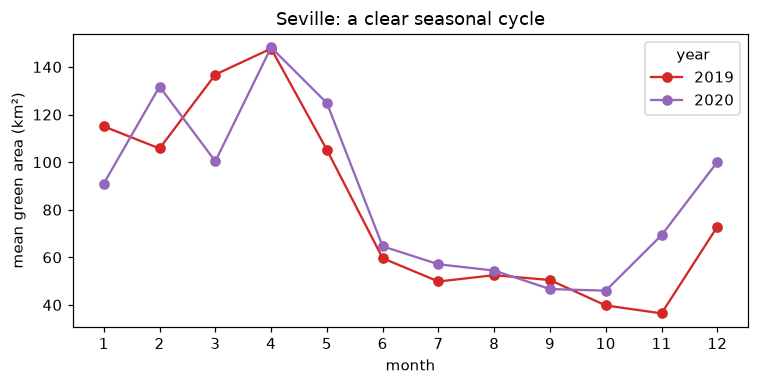

In [3]:
sev = clean[clean.region == "Seville (reference)"]
monthly = sev.groupby(["year", "month"])["green area"].mean().unstack(0)
ax = monthly.plot(marker="o", figsize=(7, 3.6), color=[f"C{y - 2016}" for y in monthly.columns])
ax.set_xlabel("month"); ax.set_ylabel("mean green area (km²)"); ax.set_title("Seville: a clear seasonal cycle")
ax.set_xticks(range(1, 13)); plt.tight_layout(); plt.savefig("../reports/seville_seasonal_cycle.png"); plt.show()

Green area rises quickly from January to about May, falls through the dry summer, and recovers toward the end of winter, and the two years agree. This is the pattern we'd expect to see if the method works.

## The Vietnamese regions

Each line is one year (2016-2021). Average green area per month, Sentinel-2 data after cleaning.

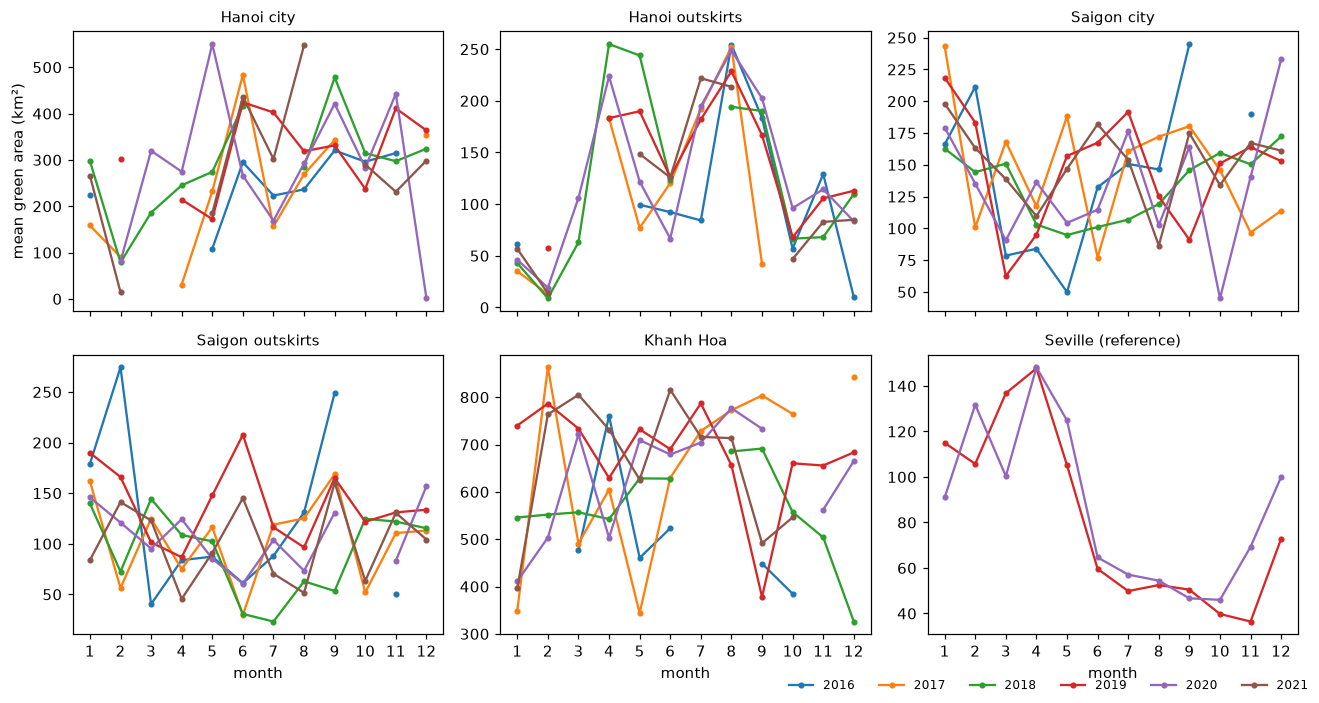

In [4]:
def seasonal_panels(satellite, fname):
    data = clean[clean.satellite == satellite]
    regions = [r for r in NAMES.values() if r in set(data.region)]
    cols = 3
    fig, axes = plt.subplots(int(np.ceil(len(regions) / cols)), cols, figsize=(12, 3.2 * np.ceil(len(regions) / cols)), sharex=True)
    for ax, region in zip(axes.flat, regions):
        m = data[data.region == region].groupby(["year", "month"])["green area"].mean().unstack(0)
        m.plot(ax=ax, marker=".", legend=False, color=[f"C{y - 2016}" for y in m.columns])  # one colour per year in every panel
        ax.set_title(region, fontsize=10); ax.set_xticks(range(1, 13)); ax.set_xlabel("month")
    for ax in list(axes.flat)[len(regions):]:
        ax.axis("off")
    axes.flat[0].set_ylabel("mean green area (km²)")
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], color=f"C{y - 2016}", marker=".", label=str(y)) for y in range(2016, 2022)]
    fig.legend(handles=handles, loc="lower right", ncol=6, fontsize=8, frameon=False)
    plt.tight_layout(); plt.savefig(fname); plt.show()

seasonal_panels("sentinel2", "../reports/monthly_green_area_sentinel2.png")

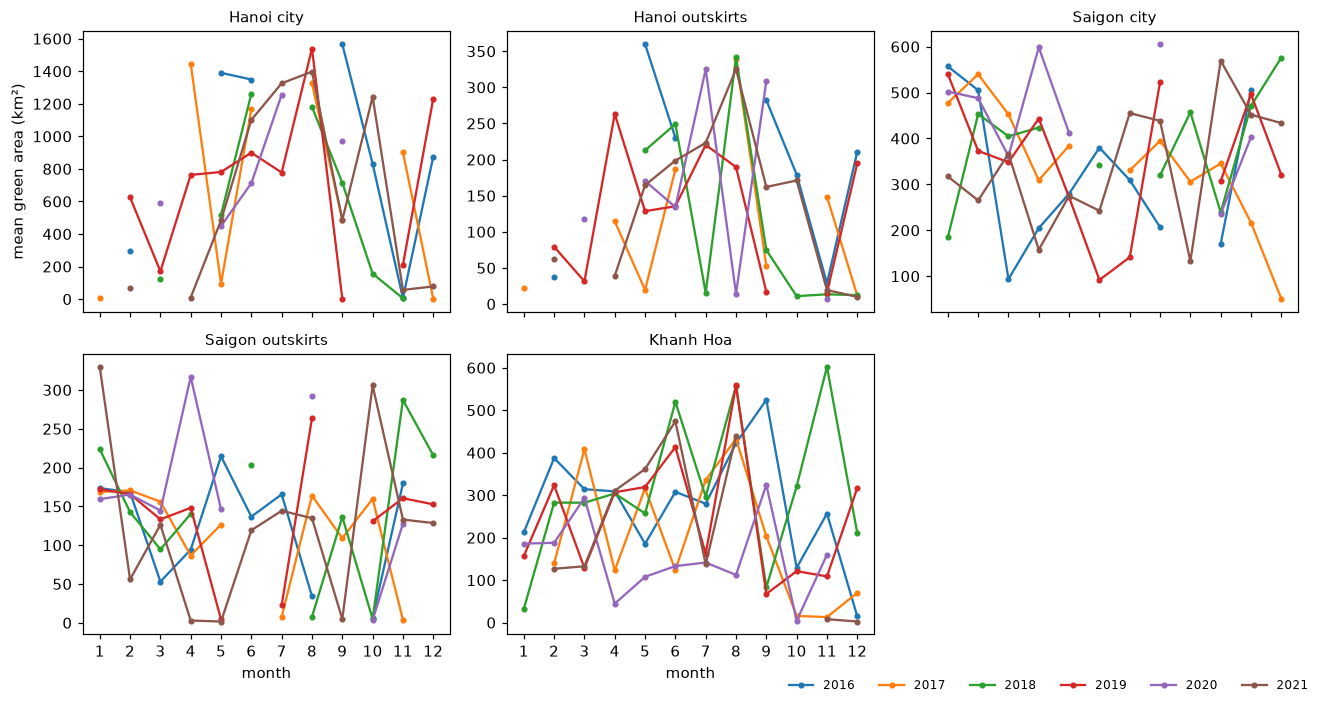

In [5]:
seasonal_panels("landsat8", "../reports/monthly_green_area_landsat8.png")

The Vietnamese regions do not show Seville's clean yearly shape. As the original study concluded, month-to-month swings are large and the pattern differs from year to year, especially in the two city centres.

## (added) How consistent is the seasonal pattern?

To put a number on "does the pattern repeat?", for each region I correlate each year's 12-month profile with every other year's and average the results. A value near 1 means every year looks the same; near 0 means the years have little in common. (Seville has only two years of data.)

In [6]:
def consistency(df):
    profile = df.groupby(["year", "month"])["green area"].mean().unstack(1)
    corr = profile.T.corr(min_periods=6).values
    pairs = corr[np.triu_indices_from(corr, k=1)]
    return np.nanmean(pairs), len(profile)

rows = []
for (region, sat), df in clean.groupby(["region", "satellite"]):
    c, years = consistency(df)
    rows.append({"region": region, "satellite": sat, "years": years, "avg year-to-year correlation": round(c, 2)})
pd.DataFrame(rows).pivot(index="region", columns="satellite", values="avg year-to-year correlation").loc[list(NAMES.values())]

satellite,landsat8,sentinel2
region,,
Hanoi city,0.40,0.35
Hanoi outskirts,0.33,0.75
Saigon city,-0.02,0.26
Saigon outskirts,-0.04,0.16
Khanh Hoa,0.18,0.03
Seville (reference),NaN,0.85


Seville's two years correlate at 0.85. Among the Vietnamese regions only Hanoi outskirts (Sentinel-2, 0.75) comes close, Hanoi city is moderate (0.35-0.40), and Saigon and Khanh Hoa show little year-to-year repeatability. So the original conclusion that the Vietnamese regions lack Seville's consistent cycle holds up. The original suggestion that the outskirts and Khanh Hoa have steadier seasonal patterns is only partly supported: true for Hanoi outskirts, not for Saigon outskirts or Khanh Hoa. Caveats: Seville has just two years, and many month-and-year cells in the cloudy regions rest on few images, so these correlations are rough.

## (added) Does cloud cover explain the noise?

The original study's main caveat was that clouds hide the ground and make images look less green. The raw data lets us check directly: the average measured green area in the raw data by cloud-cover bucket (Sentinel-2).

In [7]:
s2 = raw[raw.satellite == "sentinel2"].copy()
s2["cloud cover"] = pd.cut(s2["cloud cover percentage"], [-0.1, 10, 30, 50, 80, 100], labels=["0-10%", "10-30%", "30-50%", "50-80%", "80-100%"])
table = s2.groupby(["region", "cloud cover"], observed=True)["green area"].mean().unstack().loc[[r for r in NAMES.values() if r in set(s2.region)]].round(0)
table

cloud cover,0-10%,10-30%,30-50%,50-80%,80-100%
region,,,,,
Hanoi city,123.0,122.0,76.0,48.0,9.0
Hanoi outskirts,94.0,66.0,72.0,43.0,7.0
Saigon city,192.0,139.0,111.0,95.0,46.0
Saigon outskirts,147.0,110.0,84.0,86.0,40.0
Khanh Hoa,768.0,616.0,476.0,352.0,177.0
Seville (reference),83.0,78.0,47.0,37.0,21.0


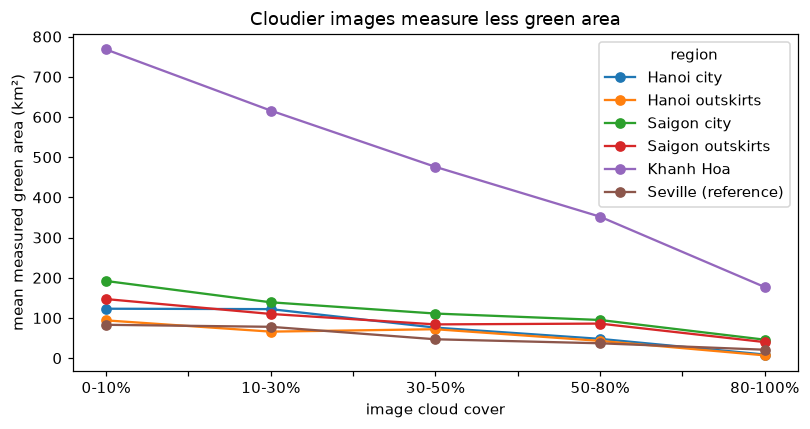

In [8]:
ax = table.T.plot(marker="o", figsize=(7.5, 4))
ax.set_ylabel("mean measured green area (km²)"); ax.set_xlabel("image cloud cover")
ax.set_title("Cloudier images measure less green area"); plt.tight_layout(); plt.savefig("../reports/cloud_cover_effect.png"); plt.show()

In the raw data, measured green area drops sharply as cloud cover increases in **every** region, Seville included, so cloud contamination is a measurement effect everywhere. Because Hanoi images are so often cloudy, a share of the month-to-month swings in cloudy Vietnamese cities is likely measurement noise rather than real change in vegetation. This agrees with the original study's conclusion that cloud cover is a major limitation.

## What this does and doesn't show

- The seasonal views reproduce the original study's picture: a clear cycle in Seville, irregular behaviour in Hanoi and Saigon, calmer outskirts and Khanh Hoa.
- I **cannot** separate real change from cloud noise with this data alone. Better would be cloud-masked imagery (e.g. per-pixel cloud masks) or composites over longer windows.
- NDVI > 0.3 can also pick up things other than the vegetation of interest, and each region's boundary is a hand-drawn polygon.